# BindingDB_Kd Dataset Investigation

**EXSU 500 — Applications of Artificial Intelligence in Experimental Surgery**

## 1. Objective

This notebook presents an exploratory investigation of the BindingDB_Kd dataset obtained through Therapeutics Data Commons (TDC). The analysis supports the development of a machine-learning regression model for predicting drug–target binding affinity from molecular structures and protein sequences.

The objectives are to:

1. Characterize the dataset and identify missing or invalid values.
2. Examine the distribution of binding-affinity measurements.
3. Convert Kd measurements into the logarithmic pKd scale.
4. Standardize molecular structures using SMILES canonicalization.
5. Identify repeated drug–target measurements.
6. Investigate the effect of retaining the strongest affinity measurement instead of the median.
7. Identify data-quality considerations relevant to preprocessing and model evaluation.

This investigation is exploratory and does not include model training or predictive performance evaluation.

## 2. Dataset and Methodology

The BindingDB_Kd dataset was accessed through the Therapeutics Data Commons Python package.

The dataset contains molecular structures represented by SMILES strings, protein-target sequences, and experimentally reported binding-affinity measurements.

The analysis was conducted using Python, pandas, NumPy, RDKit, and Matplotlib.

Only positive Kd measurements were retained for logarithmic transformation. Binding affinities were converted from Kd in nanomolar units to pKd using:

\[
pK_d = 9 - \log_{10}(K_d)
\]

where Kd is expressed in nM.

Molecular structures were canonicalized using RDKit. Unique drug–target pairs were defined using canonical SMILES and protein sequence.

For pairs with repeated measurements, the strongest pKd value and median pKd value were compared to evaluate sensitivity to duplicate aggregation.

In [15]:

%pip install -q rdkit fuzzywuzzy
%pip install -q --no-deps PyTDC


In [16]:

%pip install -q rdkit fuzzywuzzy
%pip install -q --no-deps PyTDC


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from tdc.multi_pred.dti import DTI

print("Imports successful!")


Imports successful!


In [18]:
data = DTI(name="BindingDB_Kd")
df = data.get_data()

print("Dataset shape:", df.shape)
display(df.head())

Found local copy...
Loading...
Done!


Dataset shape: (52274, 5)


,Drug_ID,Drug,Target_ID,Target,Y
0,444607.0,Cc1ccc(CNS(=O)(=O)c2ccc(S(N)(=O)=O)s2)cc1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.46
1,4316.0,COc1ccc(CNS(=O)(=O)c2ccc(S(N)(=O)=O)s2)cc1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.49
2,4293.0,NS(=O)(=O)c1ccc(S(=O)(=O)NCc2cccs2)s1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.83
3,1611.0,NS(=O)(=O)c1cc2c(s1)S(=O)(=O)N(Cc1cccs1)CC2O,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.20
4,1612.0,COc1ccc(N2CC(O)c3cc(S(N)(=O)=O)sc3S2(=O)=O)cc1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.16


In [19]:
print("Total records:", len(df))

Total records: 52274


In [20]:
print("Unique drug structures:", df["Drug"].nunique())
print("Unique protein sequences:", df["Target"].nunique())

print("\nMissing values per column:")
print(df.isna().sum())

Unique drug structures: 10661
Unique protein sequences: 1413

Missing values per column:
Drug_ID         0
Drug            0
Target_ID    4333
Target          0
Y               0
dtype: int64


In [21]:

print("Summary of Kd measurements:")
print(df["Y"].describe())

print("\nZero Kd values:", (df["Y"] == 0).sum())
print("Negative Kd values:", (df["Y"] < 0).sum())

print("\nKd = 10,000 nM:", (df["Y"] == 10000).sum())
print("Kd > 10,000 nM:", (df["Y"] > 10000).sum())


Summary of Kd measurements:
count    5.227400e+04
mean     4.353189e+04
std      4.102312e+05
min      0.000000e+00
25%      2.200000e+02
50%      9.800000e+03
75%      1.000000e+04
max      1.000000e+07
Name: Y, dtype: float64

Zero Kd values: 2
Negative Kd values: 0

Kd = 10,000 nM: 22184
Kd > 10,000 nM: 3932


In [22]:

# Keep only valid positive Kd measurements
df_clean = df[df["Y"] > 0].copy()

# Convert Kd (nM) to pKd
df_clean["pKd"] = 9 - np.log10(df_clean["Y"])

print("Records after cleaning:", len(df_clean))

print("\npKd summary:")
print(df_clean["pKd"].describe())


Records after cleaning: 52272

pKd summary:
count    52272.000000
mean         5.888650
std          1.394610
min          2.000000
25%          5.000000
50%          5.007228
75%          6.657577
max         15.000000
Name: pKd, dtype: float64


In [23]:

# Function to canonicalize molecular SMILES
def canonicalize_smiles(smiles):
    if pd.isna(smiles):
        return None

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    return Chem.MolToSmiles(mol, canonical=True)


# Create a working copy
df_pairs = df_clean.copy()

# Canonicalize drug structures
df_pairs["canonical_drug"] = df_pairs["Drug"].apply(
    canonicalize_smiles
)

print("Invalid SMILES:",
      df_pairs["canonical_drug"].isna().sum())

# Remove invalid molecular structures, if any
df_pairs = df_pairs.dropna(
    subset=["canonical_drug", "Target"]
).copy()

# Identify unique drug-target pairs
pair_columns = ["canonical_drug", "Target"]

duplicate_count = df_pairs.duplicated(
    subset=pair_columns
).sum()

unique_pair_count = df_pairs.drop_duplicates(
    subset=pair_columns
).shape[0]

print("Duplicate extra records:", duplicate_count)
print("Unique drug-target pairs:", unique_pair_count)


Invalid SMILES: 0
Duplicate extra records: 6157
Unique drug-target pairs: 46115


In [24]:

# Calculate strongest affinity for each pair
strongest_pairs = (
    df_pairs.groupby(pair_columns, as_index=False)["pKd"]
    .max()
    .rename(columns={"pKd": "strongest_pKd"})
)

# Calculate median affinity for each pair
median_pairs = (
    df_pairs.groupby(pair_columns, as_index=False)["pKd"]
    .median()
    .rename(columns={"pKd": "median_pKd"})
)

# Compare the two approaches
comparison = strongest_pairs.merge(
    median_pairs,
    on=pair_columns
)

comparison["difference"] = (
    comparison["strongest_pKd"] -
    comparison["median_pKd"]
)

# Identify pairs with different labels
affected = comparison[
    comparison["difference"] > 1e-8
].copy()

print("Total unique pairs:", len(comparison))
print("Pairs affected:", len(affected))
print("Percentage affected:",
      round(100 * len(affected) / len(comparison), 2))

print("Mean difference among affected pairs:",
      affected["difference"].mean())

print("Maximum difference:",
      comparison["difference"].max())


Total unique pairs: 46115
Pairs affected: 3488
Percentage affected: 7.56
Mean difference among affected pairs: 0.8015598937261633
Maximum difference: 8.0


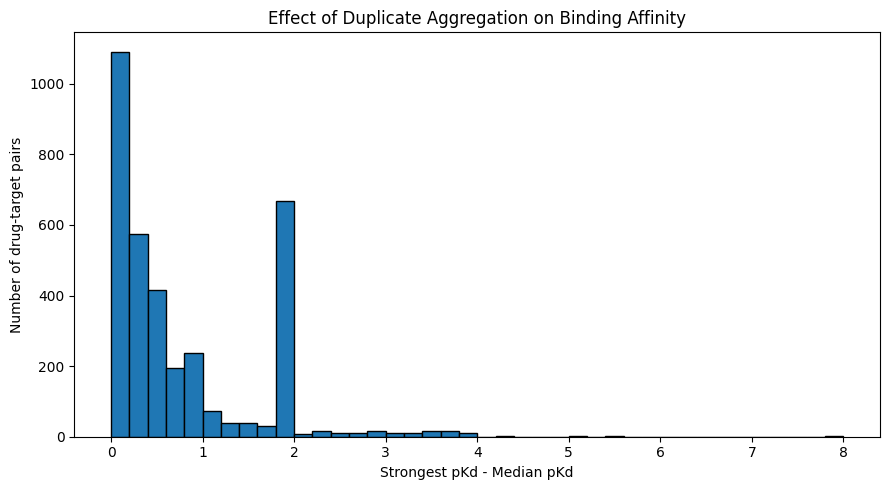

In [25]:

plt.figure(figsize=(9, 5))

plt.hist(
    affected["difference"],
    bins=40,
    edgecolor="black"
)

plt.xlabel("Strongest pKd - Median pKd")
plt.ylabel("Number of drug-target pairs")
plt.title("Effect of Duplicate Aggregation on Binding Affinity")

plt.tight_layout()

plt.savefig(
    "duplicate_aggregation_effect.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


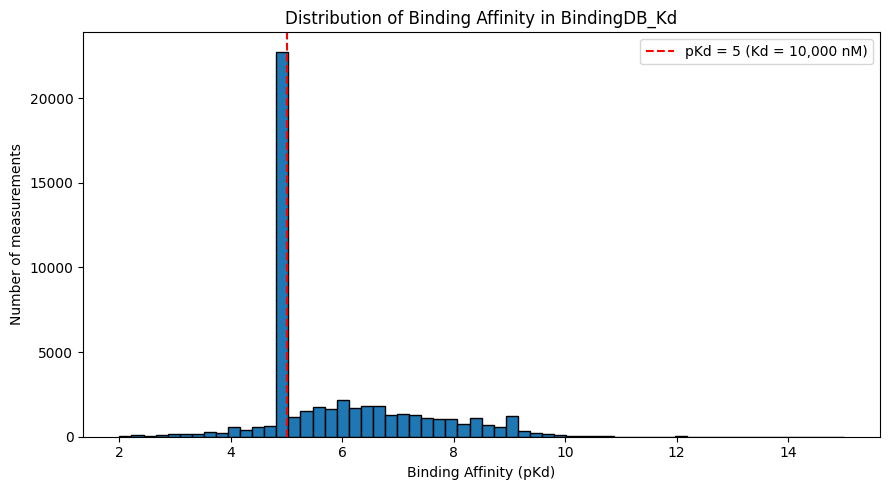

In [26]:

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["pKd"],
    bins=60,
    edgecolor="black"
)

plt.axvline(
    x=5,
    color="red",
    linestyle="--",
    label="pKd = 5 (Kd = 10,000 nM)"
)

plt.xlabel("Binding Affinity (pKd)")
plt.ylabel("Number of measurements")
plt.title("Distribution of Binding Affinity in BindingDB_Kd")

plt.legend()
plt.tight_layout()

plt.savefig(
    "bindingdb_pkd_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [27]:


# Calculate repeated measurements independently
pair_sizes = df_pairs.groupby(pair_columns).size()
repeated_pairs = (pair_sizes > 1).sum()

# Calculate pairs affected by aggregation independently
affected_pairs = (comparison["difference"] > 1e-8).sum()

# Create the final summary table
summary = pd.DataFrame({
    "Measurement": [
        "Raw dataset records",
        "Unique drug structures",
        "Unique protein sequences",
        "Missing Target_ID values",
        "Zero Kd measurements",
        "Valid positive-Kd records",
        "Records at Kd = 10,000 nM",
        "Percentage at Kd = 10,000 nM",
        "Invalid SMILES",
        "Unique drug-target pairs",
        "Pairs with repeated measurements",
        "Maximum measurements per pair",
        "Pairs affected by aggregation",
        "Mean difference among affected pairs",
        "Maximum pKd difference"
    ],
    "Value": [
        len(df),
        df["Drug"].nunique(),
        df["Target"].nunique(),
        df["Target_ID"].isna().sum(),
        (df["Y"] == 0).sum(),
        len(df_clean),
        (df["Y"] == 10000).sum(),
        round(100 * (df["Y"] == 10000).mean(), 2),
        df_clean["Drug"].apply(canonicalize_smiles).isna().sum(),
        len(comparison),
        repeated_pairs,
        pair_sizes.max(),
        affected_pairs,
        round(affected["difference"].mean(), 4),
        comparison["difference"].max()
    ]
})

# Display the summary table
display(summary)

# Save the summary table as a CSV file
summary.to_csv(
    "bindingdb_investigation_summary.csv",
    index=False
)

print("Summary table saved successfully!")


,Measurement,Value
0,Raw dataset records,52274.0000
1,Unique drug structures,10661.0000
2,Unique protein sequences,1413.0000
3,Missing Target_ID values,4333.0000
4,Zero Kd measurements,2.0000
5,Valid positive-Kd records,52272.0000
6,"Records at Kd = 10,000 nM",22184.0000
7,"Percentage at Kd = 10,000 nM",42.4400
8,Invalid SMILES,0.0000
9,Unique drug-target pairs,46115.0000


Summary table saved successfully!


In [28]:

# Count measurements for each unique drug-target pair
pair_sizes = df_pairs.groupby(pair_columns).size()

# Count pairs with more than one measurement
repeated_pairs = (pair_sizes > 1).sum()

# Count pairs whose strongest and median labels differ
affected_pairs = (comparison["difference"] > 1e-8).sum()

print("Pairs with repeated measurements:", repeated_pairs)
print("Pairs affected by aggregation:", affected_pairs)
print("Extra duplicate records:", len(df_pairs) - len(pair_sizes))


Pairs with repeated measurements: 3488
Pairs affected by aggregation: 3488
Extra duplicate records: 6157


## 3. Results and Scientific Interpretation

### 3.1 Dataset characteristics and data quality

The BindingDB_Kd dataset contained 52,274 records, representing 10,661 unique molecular SMILES strings and 1,413 unique protein sequences.

Although 4,333 records lacked a Target_ID, all records contained molecular structures, protein sequences, and affinity measurements. Therefore, missing target identifiers did not prevent the use of protein sequences for identifying drug–target pairs.

Two records contained Kd values of zero and were excluded before logarithmic transformation, leaving 52,272 positive-Kd measurements.

### 3.2 Binding-affinity distribution

Following conversion from Kd to pKd, the mean binding affinity was 5.889, with a median of 5.007 and standard deviation of 1.395. The observed pKd values ranged from 2 to 15.

A substantial concentration of measurements occurred at Kd = 10,000 nM, corresponding to pKd = 5. Specifically, 22,184 measurements (42.44% of the original dataset) had this value.

This concentration could influence model training and evaluation because a large proportion of observations share the same affinity label. However, the available numerical values alone do not establish whether these observations represent experimentally censored measurements.

The extreme pKd values, particularly those approaching 15, also warrant further investigation.

### 3.3 Drug–target duplicates

After excluding nonpositive Kd measurements and canonicalizing molecular structures using RDKit, 46,115 unique drug–target pairs were identified.

A total of 6,157 records represented additional observations of previously occurring drug–target pairs. Of the 46,115 unique pairs, 3,488 had repeated measurements, with up to 27 measurements for a single pair.

These results demonstrate that repeated experimental observations are present in the dataset and must be addressed during preprocessing.

### 3.4 Sensitivity to duplicate aggregation

To investigate the impact of duplicate handling, the strongest binding affinity (maximum pKd) was compared with the median pKd for each unique drug–target pair.

The analysis found that 3,488 pairs (7.56%) had different affinity labels depending on the aggregation strategy.

Among these affected pairs, the mean difference between strongest and median pKd was 0.8016 units, with a maximum difference of 8 units.

These findings indicate that selecting the strongest reported binding affinity can substantially change the assigned label for a subset of drug–target pairs.

The analysis does not establish which aggregation strategy is more accurate. However, it highlights the importance of documenting the selected method and considering its potential influence on model performance.

### 3.5 Implications for machine-learning development

The investigation identifies several considerations for the team's regression model.

First, the concentration of observations at pKd = 5 supports evaluating model performance across different affinity ranges rather than relying exclusively on overall performance metrics.

Second, the presence of repeated measurements suggests that the aggregation strategy may influence the labels used during model training.

Third, canonical molecular representations are important for implementing drug-level data splitting and minimizing the risk of molecular overlap between training and test sets.

Finally, extreme affinity values and possible measurement censoring should be considered when interpreting model predictions.

### 3.6 Comparison with the team's evaluation protocol

The team's evaluation protocol reports 52,284 raw records and 42,236 pairs following duplicate handling.

In comparison, this investigation identified 52,274 raw records and 46,115 unique pairs after excluding two zero-Kd measurements and grouping by canonical SMILES and protein sequence.

These differences have not yet been reconciled. They may reflect differences in dataset versions, filtering criteria, or preprocessing implementation.

The discrepancy should be investigated before finalizing the modelling dataset.

## 4. Limitations

This investigation was limited to the information available through the TDC BindingDB_Kd dataset.

The original experimental measurement qualifiers were not examined, preventing definitive identification of censored observations.

Assay-specific sources of measurement variability were not evaluated, and extreme affinity measurements were not independently verified.

Furthermore, this analysis did not involve model training, so the effect of different aggregation strategies on predictive performance remains unknown.

## 5. Conclusion

The BindingDB_Kd dataset contains a substantial number of drug–target affinity measurements suitable for exploratory modelling, but several preprocessing considerations require attention.

The pronounced concentration of measurements at pKd = 5, repeated drug–target observations, and sensitivity to duplicate aggregation demonstrate the importance of careful data preparation.

These findings provide a foundation for transparent preprocessing decisions and further investigation before model development and evaluation.